<a href="https://colab.research.google.com/github/sourish-bhattacharyya/fds-lab/blob/main/Sourish_Bhattcharyya_EXP_5_FDS_16014225009.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
from google.colab import files

uploaded = files.upload()

Saving kolkata_unified_dataset.csv to kolkata_unified_dataset.csv


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("kolkata_unified_dataset.csv")
df.head()

,Timestamp,Farm_ID,Volumetric_Moisture_Pct,Sensor_Board_Temperature_C,Raw_Capacitive_ADC,Sensor_Voltage_V,Atm_Pressure_inHg,Atm_Temperature_C,Soil_Temperature_C,SM_Level_15cm,...,SM_Volume_Pct,Hour,Day,Month,DayOfWeek,DayOfYear,Hour_sin,Hour_cos,Day_sin,Day_cos
0,2025-01-05 00:00:00,Kolkata_Farm_1,14.15,17.026336,704,2.271,30.0206,16.38,19.21,1.80,...,21.21,0,5,1,6,5,0.000000,1.000000,0.085965,0.996298
1,2025-01-05 00:15:00,Kolkata_Farm_1,14.14,17.717099,692,2.232,30.0171,17.05,19.36,2.07,...,21.16,0,5,1,6,5,0.000000,1.000000,0.085965,0.996298
2,2025-01-05 00:30:00,Kolkata_Farm_1,14.14,13.012097,700,2.258,30.0167,16.88,19.55,1.91,...,21.06,0,5,1,6,5,0.000000,1.000000,0.085965,0.996298
3,2025-01-05 00:45:00,Kolkata_Farm_1,14.14,14.360777,697,2.248,30.0192,16.39,19.52,2.02,...,20.82,0,5,1,6,5,0.000000,1.000000,0.085965,0.996298
4,2025-01-05 01:00:00,Kolkata_Farm_1,14.14,15.489267,675,2.177,30.0195,16.72,19.73,2.67,...,20.25,1,5,1,6,5,0.258819,0.965926,0.085965,0.996298


In [8]:
target = "Volumetric_Moisture_Pct"
true_values = df[target].copy()

np.random.seed(42)
miss_idx = np.random.choice(df.index, size=int(0.10 * len(df)), replace=False)
df.loc[miss_idx, target] = np.nan

print("Missing values before:", df[target].isnull().sum())

known = df[df[target].notnull()]
missing = df[df[target].isnull()]

Missing values before: 2131


In [9]:
x = known["Raw_Capacitive_ADC"].values
y = known[target].values

x_mean = x.mean()
y_mean = y.mean()
w1 = np.sum((x - x_mean) * (y - y_mean)) / np.sum((x - x_mean) ** 2)
w0 = y_mean - w1 * x_mean

print("Simple Linear Regression")
print("w0 =", round(w0, 4))
print("w1 =", round(w1, 4))

slr_pred = w0 + w1 * missing["Raw_Capacitive_ADC"].values

Simple Linear Regression
w0 = 36.2923
w1 = -0.0328


In [10]:
features = ["Raw_Capacitive_ADC", "Atm_Pressure_inHg", "Soil_Temperature_C", "Atm_Temperature_C", "SM_Volume_Pct"]

X = known[features].values
X = np.c_[np.ones(len(X)), X]
b = np.linalg.inv(X.T @ X) @ X.T @ y

print("Multiple Linear Regression")
print("b0 =", round(b[0], 4))
for name, coef in zip(features, b[1:]):
    print(name, "=", round(coef, 4))

Xm = missing[features].values
Xm = np.c_[np.ones(len(Xm)), Xm]
mlr_pred = Xm @ b

Multiple Linear Regression
b0 = 51.6525
Raw_Capacitive_ADC = -0.032
Atm_Pressure_inHg = -0.5319
Soil_Temperature_C = -0.0186
Atm_Temperature_C = 0.0134
SM_Volume_Pct = 0.0113


In [11]:
actual = true_values[missing.index].values

def evaluate(actual, pred):
    err = actual - pred
    mae = np.mean(np.abs(err))
    rmse = np.sqrt(np.mean(err ** 2))
    ss_res = np.sum(err ** 2)
    ss_tot = np.sum((actual - actual.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot
    return mae, rmse, r2

mean_pred = np.full(len(actual), y_mean)

results = pd.DataFrame(
    [evaluate(actual, mean_pred), evaluate(actual, slr_pred), evaluate(actual, mlr_pred)],
    columns=["MAE", "RMSE", "R2"],
    index=["Mean Imputation", "Simple Linear Regression", "Multiple Linear Regression"],
)
print("Accuracy on the artificially removed values")
print(results.round(4))

Accuracy on the artificially removed values
                               MAE    RMSE      R2
Mean Imputation             1.5549  2.0486 -0.0003
Simple Linear Regression    0.4425  0.5555  0.9265
Multiple Linear Regression  0.4349  0.5461  0.9289


In [12]:
df.loc[missing.index, target] = mlr_pred
print("Missing values after:", df[target].isnull().sum())

comparison = pd.DataFrame({
    "Actual": actual,
    "SLR_Predicted": slr_pred,
    "MLR_Predicted": mlr_pred,
})
comparison.head(10).round(3)

Missing values after: 0


,Actual,SLR_Predicted,MLR_Predicted
0,14.07,13.269,13.256
1,14.05,12.778,12.799
2,13.84,12.942,12.981
3,13.57,12.680,12.692
4,13.37,13.171,13.164
5,13.34,12.843,12.872
6,13.32,12.811,12.843
7,13.18,13.007,13.016
8,13.05,12.614,12.704
9,12.97,12.745,12.810


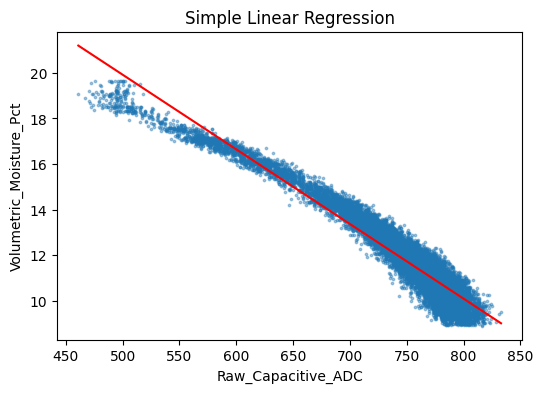

In [13]:
plt.figure(figsize=(6, 4))
plt.scatter(known["Raw_Capacitive_ADC"], known[target], s=3, alpha=0.4)
xs = np.linspace(x.min(), x.max(), 100)
plt.plot(xs, w0 + w1 * xs, color="red")
plt.xlabel("Raw_Capacitive_ADC")
plt.ylabel(target)
plt.title("Simple Linear Regression")
plt.show()

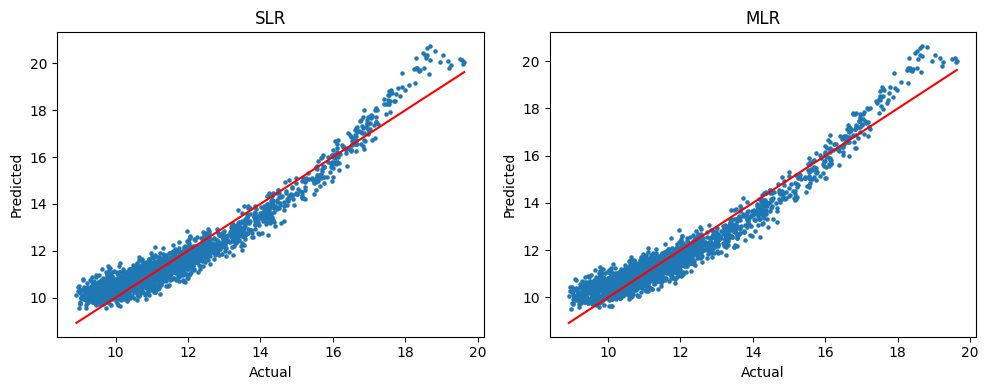

In [14]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.scatter(actual, slr_pred, s=5)
plt.plot([actual.min(), actual.max()], [actual.min(), actual.max()], color="red")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("SLR")

plt.subplot(1, 2, 2)
plt.scatter(actual, mlr_pred, s=5)
plt.plot([actual.min(), actual.max()], [actual.min(), actual.max()], color="red")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("MLR")

plt.tight_layout()
plt.show()